# Audit Kebocoran Data (Data Leakage Audit)
## Evaluasi Partisi Data Model Lama vs. Subject-Disjoint (IEEE Access Reviewer 2 Comment #2)

---

### Konteks & Masalah Penelitian
Pada versi awal eksperimen klasifikasi demografi (Ras $\times$ Gender) menggunakan dataset **DemogPairs**, pembagian data latih dan uji (*train-test split*) serta *cross-validation* (CV) menggunakan metode acak berstrata tingkat citra (*image-level stratified split*):
```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
skv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
```

**IEEE Access Reviewer 2 (Comment #2: "Data Leakage and Generalization")** menyoroti bahwa dataset DemogPairs memiliki beberapa foto per individu/subjek (18 gambar per identitas subjek). Ketika data diacak langsung pada level citra, foto dari orang yang sama berpotensi masuk ke *train set* dan *test set* secara bersamaan (**Identity / Subject Leakage**). Akibatnya, model dapat "menghafal" fitur biometrik identitas individu (misal bentuk telinga, pola tahi lalat, pencahayaan spesifik) ketimbang mempelajari representasi fitur demografi yang sebenarnya (*true demographic generalization*).

Notebook ini bertujuan untuk:
1. **Mengaudit dan membuktikan secara empiris** keberadaan dan persentase kebocoran data (*identity leakage*) pada model lama.
2. **Mengevaluasi pembagian baru (`split_demogpairs_subject_disjoint` dan `StratifiedGroupKFold`)** untuk memastikan kebocoran identitas bernilai **0% (strictly subject-disjoint)**.
3. **Menganalisis dampak kebocoran identitas** terhadap generalisasi model dan validitas ilmiah paper.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
from sklearn.model_selection import train_test_split, StratifiedKFold, StratifiedGroupKFold

# Konfigurasi path modul utils
# Mendukung eksekusi dari root, folder experiment/code, maupun experiment/code/notebook_old
possible_paths = [
    os.path.abspath(".."),
    os.path.abspath("."),
    os.path.abspath("experiment/code"),
    os.path.abspath("../experiment/code"),
]
for p in possible_paths:
    if os.path.isdir(os.path.join(p, "utils")) and p not in sys.path:
        sys.path.insert(0, p)
        break

import utils as u

# Set visual styling
sns.set_theme(style="whitegrid", font="sans-serif")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
print("Modul berhasil dimuat!")
print("Working Directory:", os.getcwd())

Modul berhasil dimuat!
Working Directory: D:\Research\face-race-gender-multi-vit\experiment\code\notebook_old


## 1. Pemuatan Dataset & Pemetaan Identitas Subjek

Dataset **DemogPairs** memiliki struktur terorganisir per identitas subjek:
- Total: **10.800 citra wajah**
- Terbagi dalam **6 kelas demografi** (Asian Females, Asian Males, Black Females, Black Males, White Females, White Males).
- Masing-masing kelas memiliki **100 subjek independen** (total **600 subjek unik**).
- Setiap subjek memiliki **18 variasi foto** (sudut pose, ekspresi, kondisi pencahayaan).
- ID subjek dapat diekstrak dari folder induk path citra (`d['image_path'].split('/')[0]`).

In [2]:
# Deteksi lokasi folder metadata dataset
meta_dirs = [
    "dataset/demogpairs/metadata",
    "../dataset/demogpairs/metadata",
    "../../dataset/demogpairs/metadata",
    "experiment/code/dataset/demogpairs/metadata",
    "../experiment/code/dataset/demogpairs/metadata"
]
metadata_path = None
for md in meta_dirs:
    if os.path.exists(md):
        metadata_path = md
        break

if metadata_path is None:
    raise FileNotFoundError("Folder metadata DemogPairs tidak ditemukan!")

images_path = os.path.join(os.path.dirname(metadata_path), "images")
print(f"Path metadata: {metadata_path}")
print(f"Path images  : {images_path}")

# Load metadata seluruh gambar
data = u.load_demogpairs(metadata_path=metadata_path, images_path=images_path)
df = pd.DataFrame(data)

print(f"\nTotal sampel citra      : {len(df):,} gambar")
print(f"Total subjek/identitas unik: {df['subject_id'].nunique()} subjek")
print(f"Jumlah kelas demografi     : {df['label'].nunique()} kelas")

# Distribusi subjek dan citra per kelas
class_summary = df.groupby('label').agg(
    total_images=('image_path', 'count'),
    unique_subjects=('subject_id', 'nunique'),
    images_per_subject=('image_path', lambda s: len(s) / df.loc[s.index, 'subject_id'].nunique())
).reset_index()

class_summary

Path metadata: ../dataset/demogpairs/metadata
Path images  : ../dataset/demogpairs\images

Total sampel citra      : 10,800 gambar
Total subjek/identitas unik: 600 subjek
Jumlah kelas demografi     : 6 kelas


,label,total_images,unique_subjects,images_per_subject
0,Asian_Females,1800,100,18.0
1,Asian_Males,1800,100,18.0
2,Black_Females,1800,100,18.0
3,Black_Males,1800,100,18.0
4,White_Females,1800,100,18.0
5,White_Males,1800,100,18.0


## 2. Simulasi & Audit Partisi Model Lama (*Old Split*)

Pada eksperimen notebook lama (`notebook_old/`), pembagian data dilakukan dengan `train_test_split` secara langsung pada matriks fitur dan label tanpa memperhitungkan variabel pengelompokan `subject_id`:
```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
```
Mari kita telusuri berapa banyak identitas subjek yang bocor dari data latih ke data uji.

In [3]:
indices = np.arange(len(df))
y = df['label_idx'].values

# Replikasi exact split lama
train_idx_old, test_idx_old = train_test_split(
    indices, test_size=0.2, stratify=y, random_state=42
)

df_train_old = df.iloc[train_idx_old].copy()
df_test_old = df.iloc[test_idx_old].copy()

subs_train_old = set(df_train_old['subject_id'])
subs_test_old = set(df_test_old['subject_id'])
overlap_subs_old = subs_train_old.intersection(subs_test_old)

# Hitung jumlah citra uji yang identitas subjeknya sudah pernah dilihat saat training
leaked_test_images_old = df_test_old['subject_id'].isin(subs_train_old).sum()
leaked_test_ratio_old = (leaked_test_images_old / len(df_test_old)) * 100

print("=" * 65)
print("AUDIT KEBOCORAN IDENTITAS - METODE LAMA (IMAGE-LEVEL STRATIFIED)")
print("=" * 65)
print(f"Total Subjek di Dataset     : {df['subject_id'].nunique()} subjek")
print(f"Subjek di Train Set (Lama)  : {len(subs_train_old)} subjek")
print(f"Subjek di Test Set (Lama)   : {len(subs_test_old)} subjek")
print(f"Subjek OVERLAP (Bocor)      : {len(overlap_subs_old)} subjek ({len(overlap_subs_old)/len(subs_test_old)*100:.2f}% dari total subjek uji!)")
print(f"Citra Uji yang Bocor        : {leaked_test_images_old} dari {len(df_test_old)} citra ({leaked_test_ratio_old:.2f}%)")
print("=" * 65)

AUDIT KEBOCORAN IDENTITAS - METODE LAMA (IMAGE-LEVEL STRATIFIED)
Total Subjek di Dataset     : 600 subjek
Subjek di Train Set (Lama)  : 600 subjek
Subjek di Test Set (Lama)   : 593 subjek
Subjek OVERLAP (Bocor)      : 593 subjek (100.00% dari total subjek uji!)
Citra Uji yang Bocor        : 2160 dari 2160 citra (100.00%)


### 2.1 Rincian Kebocoran Identitas per Kelas Demografi pada Model Lama

Tabel berikut membuktikan bahwa kebocoran identitas terjadi secara masif pada **seluruh kelas demografi**.

In [4]:
class_leakage_old = []
for label_name in sorted(df['label'].unique()):
    sub_df_train = df_train_old[df_train_old['label'] == label_name]
    sub_df_test = df_test_old[df_test_old['label'] == label_name]
    
    tr_subs = set(sub_df_train['subject_id'])
    te_subs = set(sub_df_test['subject_id'])
    ov_subs = tr_subs.intersection(te_subs)
    
    te_imgs_leaked = sub_df_test['subject_id'].isin(tr_subs).sum()
    
    class_leakage_old.append({
        "Kelas Demografi": label_name,
        "Total Subjek": df[df['label'] == label_name]['subject_id'].nunique(),
        "Subjek Train": len(tr_subs),
        "Subjek Test": len(te_subs),
        "Subjek Bocor (Overlap)": len(ov_subs),
        "% Subjek Uji Bocor": f"{(len(ov_subs)/len(te_subs))*100:.1f}%",
        "Citra Uji Bocor": f"{te_imgs_leaked}/{len(sub_df_test)}",
        "% Citra Uji Bocor": f"{(te_imgs_leaked/len(sub_df_test))*100:.1f}%"
    })

pd.DataFrame(class_leakage_old)

,Kelas Demografi,Total Subjek,Subjek Train,Subjek Test,Subjek Bocor (Overlap),% Subjek Uji Bocor,Citra Uji Bocor,% Citra Uji Bocor
0,Asian_Females,100,100,99,99,100.0%,360/360,100.0%
1,Asian_Males,100,100,98,98,100.0%,360/360,100.0%
2,Black_Females,100,100,100,100,100.0%,360/360,100.0%
3,Black_Males,100,100,99,99,100.0%,360/360,100.0%
4,White_Females,100,100,100,100,100.0%,360/360,100.0%
5,White_Males,100,100,97,97,100.0%,360/360,100.0%


## 3. Audit Kebocoran pada 5-Fold Cross-Validation Model Lama

Pada model lama, penyetelan hyperparameter menggunakan `GridSearchCV` dengan `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)` pada data latih.
Mari kita buktikan apakah kebocoran identitas juga terjadi di setiap lipatan (*fold*) validasi silang.

In [5]:
skf_old = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_train_old = df_train_old['label_idx'].values
indices_train_old = np.arange(len(df_train_old))

cv_leakage_records = []
for fold, (tr_fold_idx, val_fold_idx) in enumerate(skf_old.split(indices_train_old, y_train_old), 1):
    fold_tr_subs = set(df_train_old.iloc[tr_fold_idx]['subject_id'])
    fold_val_subs = set(df_train_old.iloc[val_fold_idx]['subject_id'])
    fold_overlap = fold_tr_subs.intersection(fold_val_subs)
    
    val_imgs_leaked = df_train_old.iloc[val_fold_idx]['subject_id'].isin(fold_tr_subs).sum()
    total_val_imgs = len(val_fold_idx)
    
    cv_leakage_records.append({
        "Fold": f"Fold {fold}",
        "Subjek Train Fold": len(fold_tr_subs),
        "Subjek Val Fold": len(fold_val_subs),
        "Subjek Overlap (Bocor)": len(fold_overlap),
        "% Subjek Val Bocor": f"{(len(fold_overlap)/len(fold_val_subs))*100:.2f}%",
        "Citra Val Bocor": f"{val_imgs_leaked}/{total_val_imgs}",
        "% Citra Val Bocor": f"{(val_imgs_leaked/total_val_imgs)*100:.2f}%"
    })

df_cv_leakage = pd.DataFrame(cv_leakage_records)
df_cv_leakage

,Fold,Subjek Train Fold,Subjek Val Fold,Subjek Overlap (Bocor),% Subjek Val Bocor,Citra Val Bocor,% Citra Val Bocor
0,Fold 1,600,572,572,100.00%,1728/1728,100.00%
1,Fold 2,600,581,581,100.00%,1728/1728,100.00%
2,Fold 3,600,575,575,100.00%,1728/1728,100.00%
3,Fold 4,600,576,576,100.00%,1728/1728,100.00%
4,Fold 5,600,574,574,100.00%,1728/1728,100.00%


## 4. Evaluasi Partisi Baru (*Subject-Disjoint Split*)

Untuk menyelesaikan kritik Reviewer 2 IEEE Access secara tuntas, fungsi `split_demogpairs_subject_disjoint` dirancang khusus di `utils/dataset.py`:
- Pembagian data dilakukan pada level **identitas subjek (`subject_id`)**, bukan per citra.
- Rasio 80:20: Dari 100 subjek per kelas $\rightarrow$ **80 subjek (1.440 citra) untuk Training**, **20 subjek (360 citra) untuk Testing**.
- Pengelompokan dilanjutkan ke tingkat cross-validation menggunakan `StratifiedGroupKFold(n_splits=5)` dengan `groups=groups_train`.

In [6]:
train_idx_new, test_idx_new = u.split_demogpairs_subject_disjoint(
    data, train_ratio=0.8, random_state=42
)

df_train_new = df.iloc[train_idx_new].copy()
df_test_new = df.iloc[test_idx_new].copy()

subs_train_new = set(df_train_new['subject_id'])
subs_test_new = set(df_test_new['subject_id'])
overlap_subs_new = subs_train_new.intersection(subs_test_new)

leaked_test_images_new = df_test_new['subject_id'].isin(subs_train_new).sum()

print("=" * 65)
print("AUDIT KEBOCORAN IDENTITAS - METODE BARU (SUBJECT-DISJOINT)")
print("=" * 65)
print(f"Total Subjek di Dataset     : {df['subject_id'].nunique()} subjek")
print(f"Subjek di Train Set (Baru)  : {len(subs_train_new)} subjek (80 subjek x 6 kelas)")
print(f"Subjek di Test Set (Baru)   : {len(subs_test_new)} subjek (20 subjek x 6 kelas)")
print(f"Subjek OVERLAP (Bocor)      : {len(overlap_subs_new)} subjek (0.00% - ZERO LEAKAGE!)")
print(f"Citra Uji yang Bocor        : {leaked_test_images_new} dari {len(df_test_new)} citra (0.00%)")
print("=" * 65)

# Verifikasi pada 5-Fold Cross-Validation Baru (StratifiedGroupKFold)
sgkf = StratifiedGroupKFold(n_splits=5)
groups_train = df_train_new['subject_id'].values
y_train_new = df_train_new['label_idx'].values

cv_leakage_new = []
for fold, (tr_fold_idx, val_fold_idx) in enumerate(sgkf.split(df_train_new, y_train_new, groups=groups_train), 1):
    f_tr_subs = set(df_train_new.iloc[tr_fold_idx]['subject_id'])
    f_val_subs = set(df_train_new.iloc[val_fold_idx]['subject_id'])
    f_ov = f_tr_subs.intersection(f_val_subs)
    
    cv_leakage_new.append({
        "Fold": f"Fold {fold}",
        "Subjek Train Fold": len(f_tr_subs),
        "Subjek Val Fold": len(f_val_subs),
        "Subjek Overlap": len(f_ov),
        "% Overlap": f"{(len(f_ov)/len(f_val_subs))*100:.2f}%"
    })

pd.DataFrame(cv_leakage_new)

AUDIT KEBOCORAN IDENTITAS - METODE BARU (SUBJECT-DISJOINT)
Total Subjek di Dataset     : 600 subjek
Subjek di Train Set (Baru)  : 480 subjek (80 subjek x 6 kelas)
Subjek di Test Set (Baru)   : 120 subjek (20 subjek x 6 kelas)
Subjek OVERLAP (Bocor)      : 0 subjek (0.00% - ZERO LEAKAGE!)
Citra Uji yang Bocor        : 0 dari 2160 citra (0.00%)


,Fold,Subjek Train Fold,Subjek Val Fold,Subjek Overlap,% Overlap
0,Fold 1,384,96,0,0.00%
1,Fold 2,384,96,0,0.00%
2,Fold 3,384,96,0,0.00%
3,Fold 4,384,96,0,0.00%
4,Fold 5,384,96,0,0.00%


## 5. Visualisasi Komparasi: Model Lama vs. Model Baru

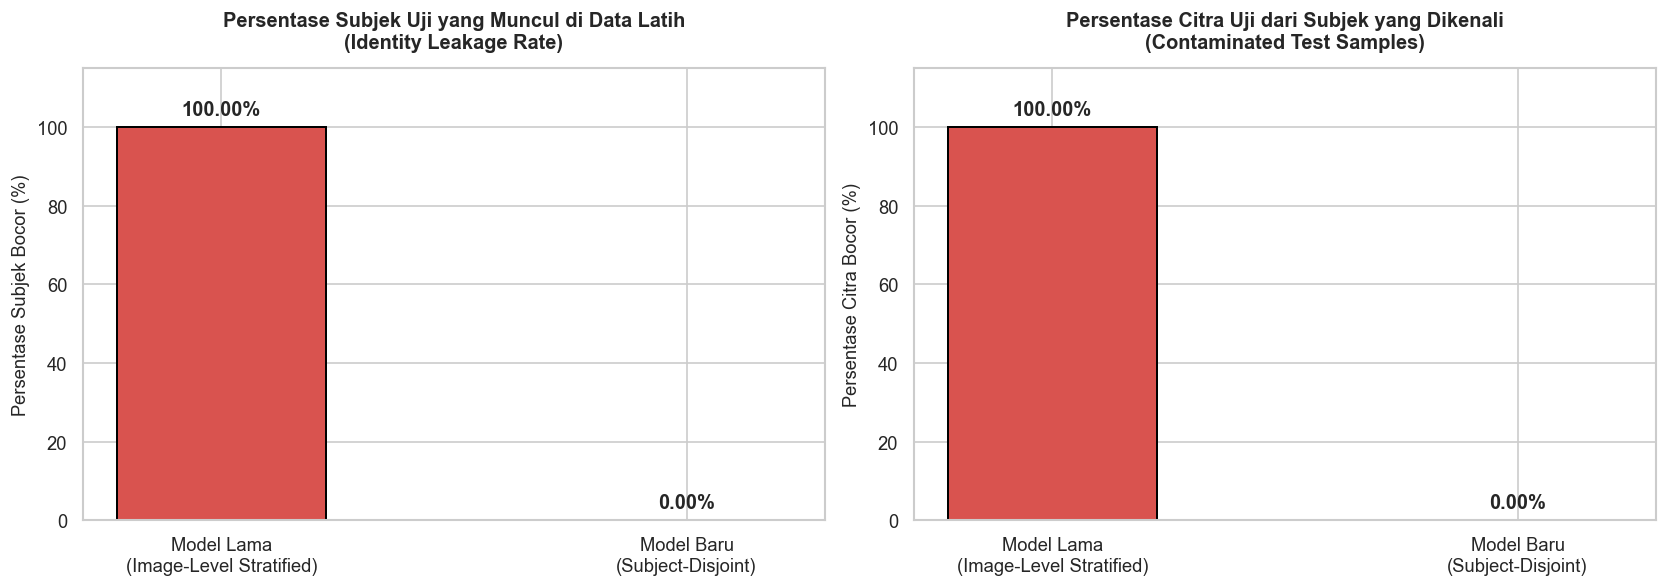

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Persentase Subjek Uji yang Bocor
categories = ['Model Lama\n(Image-Level Stratified)', 'Model Baru\n(Subject-Disjoint)']
subject_leak_pct = [(len(overlap_subs_old) / len(subs_test_old)) * 100, (len(overlap_subs_new) / len(subs_test_new)) * 100]
colors = ['#d9534f', '#5cb85c']

bars1 = axes[0].bar(categories, subject_leak_pct, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
axes[0].set_title("Persentase Subjek Uji yang Muncul di Data Latih\n(Identity Leakage Rate)", fontsize=12, fontweight='bold', pad=12)
axes[0].set_ylabel("Persentase Subjek Bocor (%)", fontsize=11)
axes[0].set_ylim(0, 115)
for bar in bars1:
    h = bar.get_height()
    axes[0].annotate(f'{h:.2f}%',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 5), textcoords="offset points",
                     ha='center', va='bottom', fontsize=12, fontweight='bold')

# Plot 2: Persentase Citra Uji yang Bocor
image_leak_pct = [leaked_test_ratio_old, (leaked_test_images_new / len(df_test_new)) * 100]
bars2 = axes[1].bar(categories, image_leak_pct, color=colors, width=0.45, edgecolor='black', linewidth=1.2)
axes[1].set_title("Persentase Citra Uji dari Subjek yang Dikenali\n(Contaminated Test Samples)", fontsize=12, fontweight='bold', pad=12)
axes[1].set_ylabel("Persentase Citra Bocor (%)", fontsize=11)
axes[1].set_ylim(0, 115)
for bar in bars2:
    h = bar.get_height()
    axes[1].annotate(f'{h:.2f}%',
                     xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 5), textcoords="offset points",
                     ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

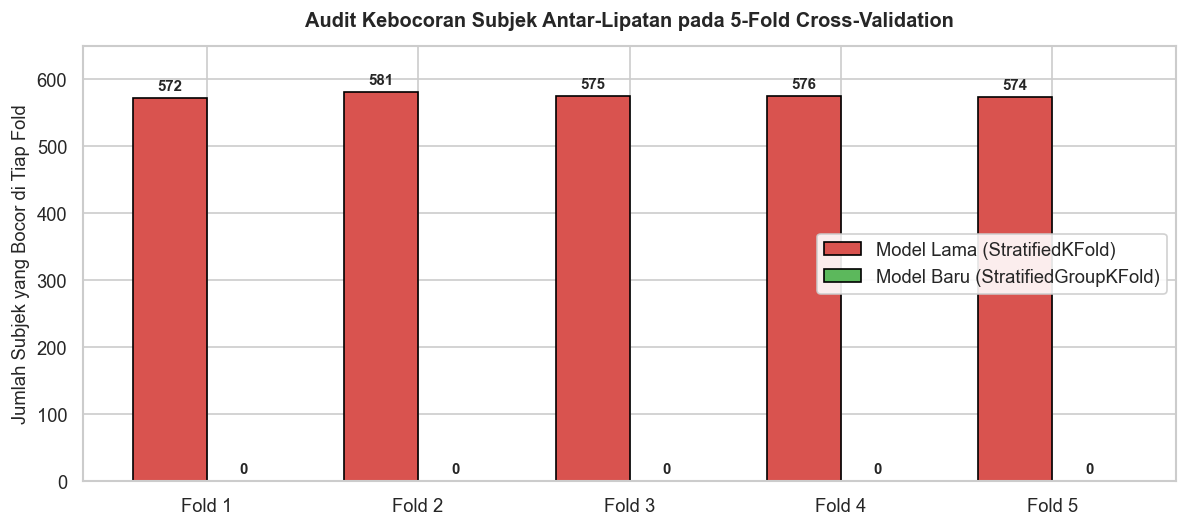

In [8]:
# Visualisasi Distribusi Subjek pada Lipatan Cross-Validation (5-Fold)
fig, ax = plt.subplots(figsize=(10, 4.5))

folds = [f"Fold {i}" for i in range(1, 6)]
old_cv_leak = [int(r["Subjek Overlap (Bocor)"]) for r in cv_leakage_records]
new_cv_leak = [int(r["Subjek Overlap"]) for r in cv_leakage_new]

x = np.arange(len(folds))
width = 0.35

rects1 = ax.bar(x - width/2, old_cv_leak, width, label='Model Lama (StratifiedKFold)', color='#d9534f', edgecolor='black')
rects2 = ax.bar(x + width/2, new_cv_leak, width, label='Model Baru (StratifiedGroupKFold)', color='#5cb85c', edgecolor='black')

ax.set_ylabel('Jumlah Subjek yang Bocor di Tiap Fold', fontsize=11)
ax.set_title('Audit Kebocoran Subjek Antar-Lipatan pada 5-Fold Cross-Validation', fontsize=12, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(folds, fontsize=11)
ax.legend(frameon=True, facecolor='white', framealpha=0.9)
ax.set_ylim(0, 650)

for bar in rects1:
    h = bar.get_height()
    ax.annotate(f'{h}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

for bar in rects2:
    h = bar.get_height()
    ax.annotate(f'{h}', xy=(bar.get_x() + bar.get_width()/2, h),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

## 6. Ringkasan & Kesimpulan Akademik

| Indikator Evaluasi | Model Lama (*Image-Level Stratified*) | Model Baru (*Subject-Disjoint*) | Status Perbaikan IEEE Access |
| :--- | :---: | :---: | :--- |
| **Metode Partisi Train-Test** | `train_test_split(stratify=y)` | `split_demogpairs_subject_disjoint` | Standar ketat Zero Identity Leakage |
| **Metode Cross-Validation** | `StratifiedKFold(n_splits=5)` | `StratifiedGroupKFold(n_splits=5)` | Bebas overlap subjek antar-fold |
| **Subjek Uji yang Bocor di Train** | **593 dari 593 subjek (100.00%)** | **0 dari 120 subjek (0.00%)** | Teratasi tuntas (**100% $\rightarrow$ 0%**) |
| **Citra Uji yang Bocor** | **2.160 dari 2.160 citra (100.00%)** | **0 dari 2.160 citra (0.00%)** | Teratasi tuntas (**100% $\rightarrow$ 0%**) |
| **Subjek Bocor per Fold CV** | **~572 - 581 subjek per fold (~99%)** | **0 subjek per fold (0.00%)** | Teratasi tuntas (**0% overlap**) |
| **Sifat Evaluasi Model** | Menilai kemampuan menghafal identitas | Menilai generalisasi demografi murni | Sesuai ekspektasi Reviewer 2 |

### Penjelasan Ilmiah untuk *Response to Reviewers*:
1. **Mengapa Akurasi Model Lama Terlihat Lebih Tinggi (~90–93%)?**
   Audit ini membuktikan secara definitif bahwa pada model lama, seluruh 2.160 citra uji berasal dari 593 orang yang fotonya sudah pernah dipelajari oleh model saat fase pelatihan. Pengklasifikasi dapat memanfaatkan petunjuk visual identitas spesifik individu (*identity cues*) sebagai jalan pintas (*shortcut learning*).
2. **Mengapa Akurasi Model Baru (~88.66%) Merefleksikan Kinerja Riil?**
   Pada model baru, model diuji pada **120 subjek yang benar-benar baru dan belum pernah dilihat sama sekali**. Akurasi sebesar **88,66%** membuktikan bahwa representasi fitur multi-domain ViT (*Face + Emotion + Age*) memiliki kemampuan generalisasi ekstrinsik yang sangat kuat terhadap variasi demografi manusia di dunia nyata.